# Time against emissions: the commutes of New York and Houston

What a lower-carbon commute costs in minutes, and where. The input is the commute table of
05.10 (run `us-v4-centre`): every tract-to-tract commuting flow of LODES with its workers and,
per mode, the door-to-door minutes, the kilometres and the one-way grams CO₂e at the US factors
of `factors/us-v4/`. Transit minutes are the median over a 30-minute departure window from 08:30.
Car minutes are cafein's midday-profile time (its lightest intersection delays, no congestion
multiplier) plus the Urban Mobility Report congestion index applied to the link time of the share
of the trip inside the metro's main urban area, plus a 3-minute parking search where the work tract
is an employment centre, at least 10,000 jobs per km² (see 05.10). Modes are transit, petrol car, bicycle and e-bike, with the BEV car as a
scenario on the car's trips; walking is not a mode of its own here and enters only as the
access and egress legs of transit. Weekly figures follow the carbon-budgets paper: four return
commutes a week, against the paper's budgets of 7 kg CO₂e per week (2030) and 3 kg (2050).

| Step | What we do |
|---|---|
| 1. Inputs | The commute tables, one wide row per flow, and the kept tracts |
| 2. Time against emissions by mode | Where each mode's commutes sit in the minutes-by-grams plane, worker-weighted, and the mode medians |
| 3. Who can leave the car | For every commuter who can drive: whether transit, the e-bike or the bicycle is available at all, and how that share grows as the driver accepts more extra minutes |
| 4. The frontier against the car | For every driver, the cleanest mode that beats the car within a margin of extra minutes: who switches, and how much of the fleet's emissions that avoids, as the margin grows |
| 5. Maps | By home tract, New York beside Houston: the time penalty of transit against the car, the share of residents with a cleaner mode within a small time cost, and compliance with the 2030 budget when drivers take the cleanest mode within that time cost |

Everything is worker-weighted: a flow counts as many commuters as it carries. A mode is
available to a commuter when it has an itinerary under the routing caps of 05.9 (120 minutes on
the street, 30-minute access and egress on transit) **and**, for the bicycle and the e-bike,
when the ride takes at most 45 minutes one way: longer rides are not a daily commute for most
people and are set aside as unavailable (`MODE_CAPS_MIN` in the parameters). A commuter without
the mode is excluded from that mode's statistics and counted as such.

In [1]:
from pathlib import Path

import contextily as ctx
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

YEAR = 2023
RUN_TAG = "us-v4.1-centre"
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

AREAS = {"New York": RESULTS / "new-york", "Houston": RESULTS / "houston", "Chicago": RESULTS / "chicago",
         "Seattle": RESULTS / "seattle", "Phoenix": RESULTS / "phoenix"}
MODES = ["transit", "car", "car_bev", "bicycle", "e_bike"]   # walking counts only as the access and egress legs of transit
COMMUTES_PER_WEEK = 4
WEEKLY_PER_GRAM = 2 * COMMUTES_PER_WEEK / 1000      # one-way grams -> weekly kg
BUDGETS_KG = {"2030 budget, 7 kg/week": 7.0, "2050 budget, 3 kg/week": 3.0}
MODE_CAPS_MIN = {"bicycle": 45, "e_bike": 45}   # a ride longer than this, one way, does not count as an available commute
TOLERANCE_MIN = 15      # maps 2 and 3: a cleaner mode counts as "within reach" when at most this much slower than the car; the frontier of step 4 sweeps the margin

# Okabe-Ito hues, one per mode, in the fixed order of 05.9 and 05.10; grey for "none".
COLOURS = {"transit": "#0072B2", "car": "#D55E00", "car_bev": "#E69F00", "bicycle": "#009E73", "e_bike": "#56B4E9", "walk": "#999999"}
LABELS = {"transit": "transit", "car": "car (petrol)", "car_bev": "car (BEV scenario)", "bicycle": "bicycle", "e_bike": "e-bike", "walk": "walk"}
SEQUENTIAL = "Blues"
DIVERGING = mcolors.LinearSegmentedColormap.from_list("transit_vs_car", ["#0072B2", "#e6e6e6", "#D55E00"])   # blue: transit faster; orange: slower
NO_DATA = "#d9d9d9"

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 9,
                     "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none", "pdf.fonttype": 42})
BASEMAP = ctx.providers.Esri.WorldGrayCanvas
ctx.set_cache_dir(str(Path.home() / ".cache" / "contextily"))

## 1. Inputs

The long commute table of each area pivoted wide, one row per flow with `minutes_<mode>`,
`km_<mode>` and `grams_<mode>`, plus the kept tract polygons for the maps.

In [2]:
def weighted_median(values, weights):
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    if len(values) == 0 or weights.sum() == 0:
        return np.nan
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


def weighted_quantiles(values, weights, quantiles):
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    if len(values) == 0 or weights.sum() == 0:
        return [np.nan] * len(quantiles)
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return [values[order][np.searchsorted(cumulative, q)] for q in quantiles]


def load_wide(folder):
    long = pd.read_parquet(folder / f"commute-emissions-{RUN_TAG}-{YEAR}.parquet", columns=["from_id", "to_id", "workers", "mode", "minutes", "km", "grams"])
    wide = long.pivot(index=["from_id", "to_id", "workers"], columns="mode", values=["minutes", "km", "grams"])
    wide.columns = [f"{value}_{mode}" for value, mode in wide.columns]
    wide = wide.reset_index()
    for mode, cap in MODE_CAPS_MIN.items():
        over = wide[f"minutes_{mode}"] > cap
        wide.loc[over, [f"minutes_{mode}", f"km_{mode}", f"grams_{mode}"]] = np.nan
    return wide


flows, tracts = {}, {}
for area, folder in AREAS.items():
    flows[area] = load_wide(folder)
    polygons = gpd.read_parquet(folder / f"tracts-kept-{YEAR}.parquet")[["tract", "geometry"]].to_crs("EPSG:3857")
    polygons["tract"] = polygons["tract"].astype(str)
    tracts[area] = polygons
    reach = {mode: flows[area].loc[flows[area][f"minutes_{mode}"].notna(), "workers"].sum() / flows[area]["workers"].sum() for mode in MODES}
    print(f"{area}: {len(flows[area]):,} flows, {flows[area]['workers'].sum():,} commuters, {len(polygons):,} tracts; share with the mode available: "
          + ", ".join(f"{LABELS[m]} {s:.2f}" for m, s in reach.items()))
print(f"bicycle and e-bike rides over {MODE_CAPS_MIN['bicycle']} min one way are set aside as unavailable")

New York: 2,408,018 flows, 6,708,469 commuters, 4,589 tracts; share with the mode available: transit 0.90, car (petrol) 0.99, car (BEV scenario) 0.99, bicycle 0.40, e-bike 0.45


Houston: 608,199 flows, 2,114,670 commuters, 1,447 tracts; share with the mode available: transit 0.31, car (petrol) 1.00, car (BEV scenario) 1.00, bicycle 0.24, e-bike 0.27


Chicago: 933,646 flows, 3,423,828 commuters, 2,153 tracts; share with the mode available: transit 0.68, car (petrol) 0.99, car (BEV scenario) 0.99, bicycle 0.32, e-bike 0.36


Seattle: 253,835 flows, 1,531,980 commuters, 791 tracts; share with the mode available: transit 0.84, car (petrol) 0.99, car (BEV scenario) 0.99, bicycle 0.32, e-bike 0.36


Phoenix: 386,194 flows, 1,748,052 commuters, 1,008 tracts; share with the mode available: transit 0.62, car (petrol) 0.99, car (BEV scenario) 0.99, bicycle 0.23, e-bike 0.27
bicycle and e-bike rides over 45 min one way are set aside as unavailable


## 2. Time against emissions by mode

Each panel is the worker-weighted density of one-way commutes in the plane of door-to-door
minutes and kilograms CO₂e, one mode per row, the two areas side by side on shared axes. The
dot and bars in each panel mark the mode's worker-weighted median and interquartile range. The
BEV scenario has its own row: the car's minutes, the BEV's grams, on the same kg axis as the
petrol car so the two rows compare directly.

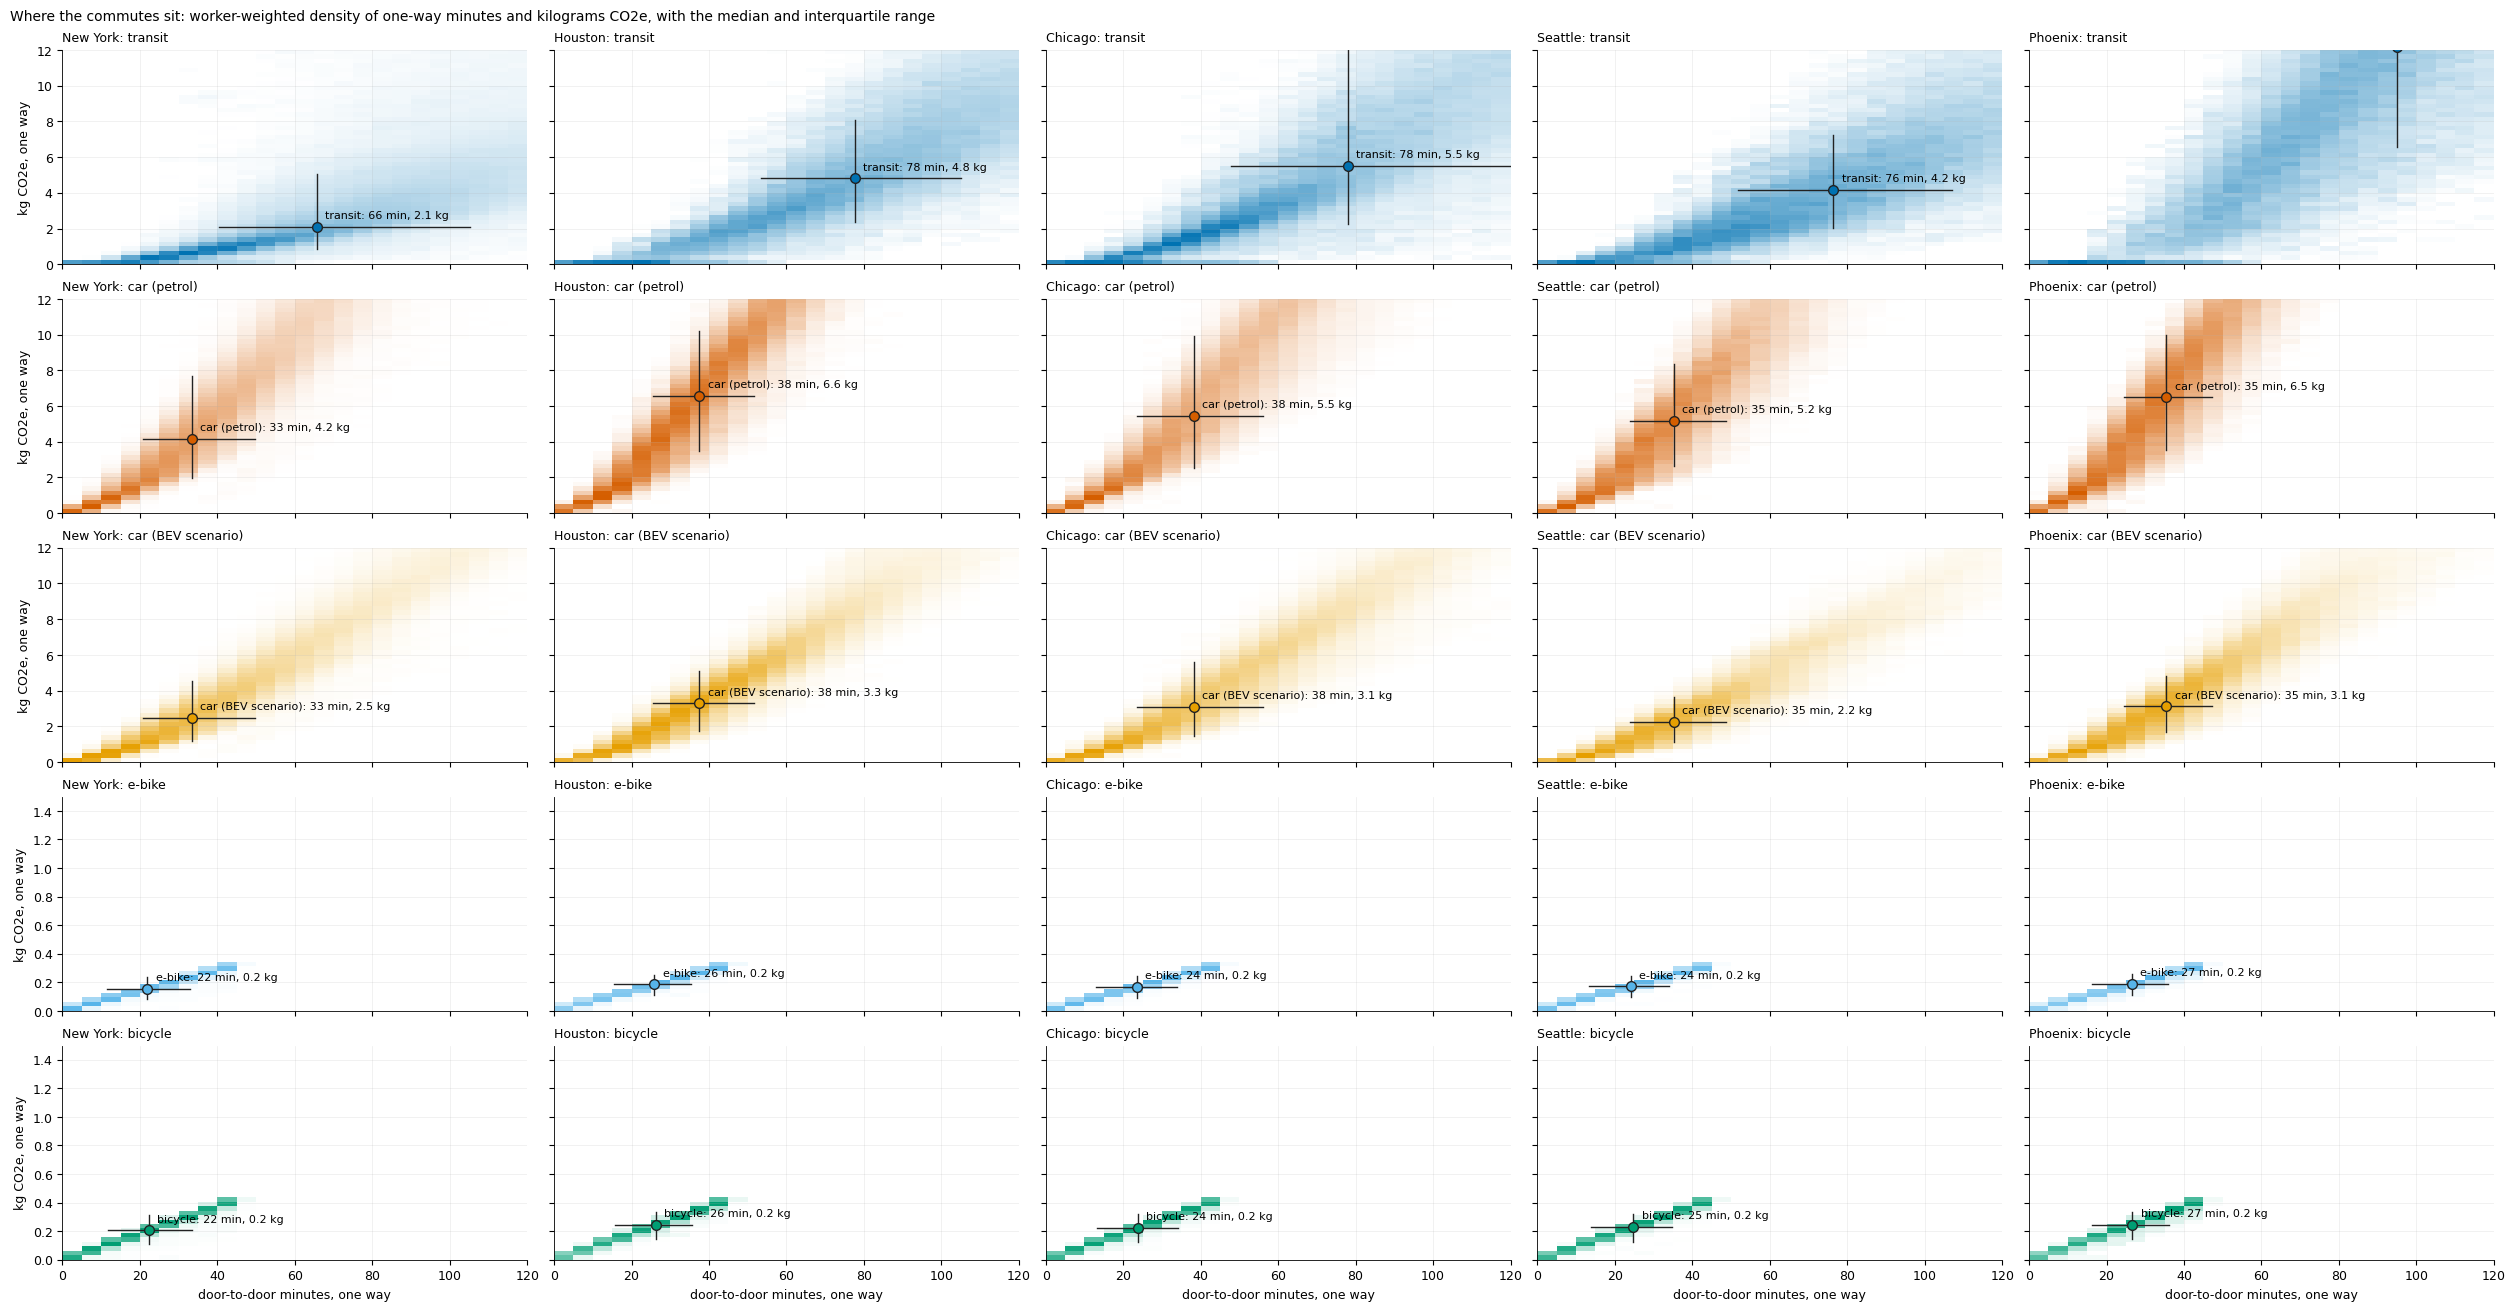

,,commuters with an itinerary,minutes p25,minutes median,minutes p75,kg p25,kg median,kg p75
area,mode,,,,,,,
New York,transit,6066192,40.4,65.7,105.2,0.9,2.1,5.0
Houston,transit,664895,53.4,77.6,105.0,2.4,4.8,8.1
Chicago,transit,2320540,47.8,78.1,131.0,2.2,5.5,12.7
Seattle,transit,1291844,51.7,76.4,107.0,2.0,4.2,7.2
Phoenix,transit,1092175,68.7,95.0,128.5,6.6,12.2,19.1
New York,car,6630009,20.8,33.4,49.7,1.9,4.2,7.7
Houston,car,2106212,25.5,37.5,51.6,3.5,6.6,10.2
Chicago,car,3394424,23.7,38.2,56.1,2.5,5.5,9.9
Seattle,car,1520697,24.0,35.2,48.7,2.6,5.2,8.4


In [3]:
MINUTE_BINS = np.arange(0, 125, 5)
PANELS = [("transit", 12), ("car", 12), ("car_bev", 12), ("e_bike", 1.5), ("bicycle", 1.5)]   # one mode per row, and the row's kg axis

figure, axes = plt.subplots(nrows=len(PANELS), ncols=len(AREAS), figsize=(5 * len(AREAS), 2.6 * len(PANELS)), sharex=True, sharey="row", layout="constrained")
mode_summary = []
for row, (mode, kg_top) in enumerate(PANELS):
    for column, (area, table) in enumerate(flows.items()):
        axis = axes[row, column]
        rows = table.loc[table[f"minutes_{mode}"].notna()]
        kg_bins = np.linspace(0, kg_top, 49)
        density, _, _ = np.histogram2d(rows[f"minutes_{mode}"], rows[f"grams_{mode}"] / 1000, bins=[MINUTE_BINS, kg_bins], weights=rows["workers"])
        density = density / rows["workers"].sum() * 100
        cmap = mcolors.LinearSegmentedColormap.from_list(mode, ["#ffffff", COLOURS[mode]])
        axis.pcolormesh(MINUTE_BINS, kg_bins, density.T, cmap=cmap, norm=mcolors.PowerNorm(0.5, vmin=0, vmax=max(density.max(), 1e-9)), rasterized=True)
        t25, t50, t75 = weighted_quantiles(rows[f"minutes_{mode}"], rows["workers"], [0.25, 0.5, 0.75])
        g25, g50, g75 = weighted_quantiles(rows[f"grams_{mode}"] / 1000, rows["workers"], [0.25, 0.5, 0.75])
        axis.plot([t25, t75], [g50, g50], color="#222222", linewidth=1)
        axis.plot([t50, t50], [g25, g75], color="#222222", linewidth=1)
        axis.plot(t50, g50, "o", markerfacecolor=COLOURS[mode], markeredgecolor="#222222", markersize=7)
        axis.annotate(f"{LABELS[mode]}: {t50:.0f} min, {g50:.1f} kg", (t50, g50), xytext=(6, 6), textcoords="offset points", fontsize=8)
        mode_summary.append({"area": area, "mode": mode, "commuters with an itinerary": int(rows["workers"].sum()),
                             "minutes p25": t25, "minutes median": t50, "minutes p75": t75, "kg p25": g25, "kg median": g50, "kg p75": g75})
        axis.set_title(f"{area}: {LABELS[mode]}", loc="left", fontsize=9)
        axis.set_ylim(0, kg_top)
        axis.grid(alpha=0.25, linewidth=0.5)
        if row == len(PANELS) - 1:
            axis.set_xlabel("door-to-door minutes, one way")
        if column == 0:
            axis.set_ylabel("kg CO2e, one way")
axes[0, 0].set_xlim(0, 120)
figure.suptitle("Where the commutes sit: worker-weighted density of one-way minutes and kilograms CO2e, with the median and interquartile range", x=0, ha="left", fontsize=10)
figure.savefig(FIGURES / f"05.11-time-vs-emissions-density-{RUN_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

mode_summary = pd.DataFrame(mode_summary).set_index(["area", "mode"])
mode_summary.round(1)

## 3. Who can leave the car, and at what time cost

For every commuter who can drive, whether transit, the e-bike or the bicycle exists as an
alternative at all, and how many drivers would have it if they accepted a given number of
extra minutes against their drive.
The curves read like accessibility curves: at zero extra minutes, the share of drivers for
whom the alternative is as fast as the car; moving right, the share who have it within 10,
20, 30 or more extra minutes; the flat end is the share who have the alternative at all. The
gap between the flat end and 100% is the share of drivers for whom the alternative does not
exist under the caps: no transit itinerary with a 30-minute walk at each end, or a ride
longer than 45 minutes. The table beside it gives the availability, the median extra minutes
among those who have the alternative, and the weekly kilograms it saves them.

alternatives to the petrol car among commuters with a car itinerary; shares are of all drivers unless stated:


available to  as fast as the car  within 15 extra min  \
area     alternative                                                          
New York transit             0.908               0.012                0.221   
         e-bike              0.451               0.170                0.434   
         bicycle             0.403               0.092                0.377   
Houston  transit             0.315               0.000                0.019   
         e-bike              0.276               0.042                0.242   
         bicycle             0.237               0.020                0.197   
Chicago  transit             0.680               0.001                0.078   
         e-bike              0.365               0.097                0.347   
         bicycle             0.321               0.047                0.294   
Seattle  transit             0.845               0.002                0.075   
         e-bike              0.364               0.137                0.338   
         bicycle             0.323               0.088                0.288   
Phoenix  transit             0.627               0.001                0.017   
         e-bike              0.271               0.031                0.227   
         bicycle             0.231               0.014                0.178   

                      within 30 extra min  \
area     alternative                        
New York transit                    0.449   
         e-bike                     0.451   
         bicycle                    0.403   
Houston  transit                    0.070   
         e-bike                     0.276   
         bicycle                    0.237   
Chicago  transit                    0.255   
         e-bike                     0.365   
         bicycle                    0.321   
Seattle  transit                    0.263   
         e-bike                     0.364   
         bicycle                    0.323   
Phoenix  transit                    0.064   
         e-bike                     0.271   
         bicycle                    0.231   

                      median extra minutes, where available  \
area     alternative                                          
New York transit                                       30.4   
         e-bike                                         1.3   
         bicycle                                        3.2   
Houston  transit                                       49.1   
         e-bike                                         5.4   
         bicycle                                        7.3   
Chicago  transit                                       41.2   
         e-bike                                         2.7   
         bicycle                                        4.7   
Seattle  transit                                       41.4   
         e-bike                                         1.9   
         bicycle                                        3.6   
Phoenix  transit                                       63.3   
         e-bike                                         6.8   
         bicycle                                        8.5   

                      median kg saved per week, where available  \
area     alternative                                              
New York transit                                           10.9   
         e-bike                                            12.9   
         bicycle                                           10.8   
Houston  transit                                           -4.5   
         e-bike                                            15.1   
         bicycle                                           12.6   
Chicago  transit                                           -4.0   
         e-bike                                            13.7   
         bicycle                                           11.4   
Seattle  transit                                            1.8   
         e-bike                     

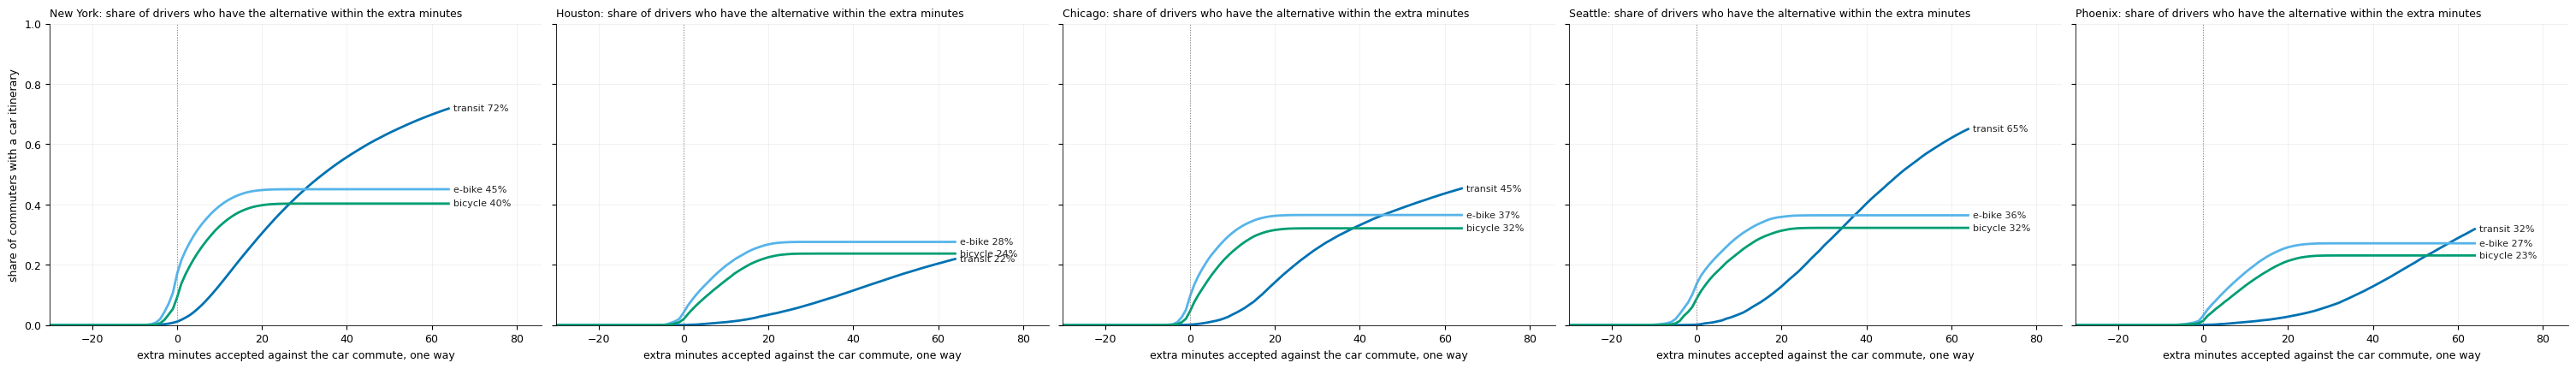

In [4]:
ALTERNATIVES = ["transit", "e_bike", "bicycle"]
EXTRA_MINUTES = np.arange(-30, 65, 1)

access_rows, curves = [], {}
for area, table in flows.items():
    drivers = table.loc[table["minutes_car"].notna()]
    total = drivers["workers"].sum()
    for mode in ALTERNATIVES:
        both = drivers.loc[drivers[f"minutes_{mode}"].notna()]
        extra = (both[f"minutes_{mode}"] - both["minutes_car"]).to_numpy()
        weights = both["workers"].to_numpy()
        saved = (both["grams_car"] - both[f"grams_{mode}"]).to_numpy() * WEEKLY_PER_GRAM
        order = np.argsort(extra)
        cumulative = np.cumsum(weights[order]) / total
        curves[(area, mode)] = np.interp(EXTRA_MINUTES, extra[order], cumulative, left=0.0)
        access_rows.append({"area": area, "alternative": LABELS[mode], "available to": weights.sum() / total,
                            "as fast as the car": weights[extra <= 0].sum() / total,
                            "within 15 extra min": weights[extra <= 15].sum() / total,
                            "within 30 extra min": weights[extra <= 30].sum() / total,
                            "median extra minutes, where available": weighted_median(extra, weights),
                            "median kg saved per week, where available": weighted_median(saved, weights),
                            "share of those who save nothing or emit more": weights[saved <= 0].sum() / max(weights.sum(), 1)})

access = pd.DataFrame(access_rows).set_index(["area", "alternative"])
print("alternatives to the petrol car among commuters with a car itinerary; shares are of all drivers unless stated:")
display(access.round({"available to": 3, "as fast as the car": 3, "within 15 extra min": 3, "within 30 extra min": 3,
                      "median extra minutes, where available": 1, "median kg saved per week, where available": 1, "share of those who save nothing or emit more": 3}))

figure, axes = plt.subplots(ncols=len(AREAS), figsize=(6 * len(AREAS), 4.2), sharey=True, layout="constrained")
for axis, area in zip(axes, AREAS):
    for mode in ALTERNATIVES:
        curve = curves[(area, mode)]
        axis.plot(EXTRA_MINUTES, curve, color=COLOURS[mode], linewidth=2)
        axis.annotate(f"{LABELS[mode]} {curve[-1]:.0%}", (EXTRA_MINUTES[-1], curve[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#222222")
    axis.axvline(0, color="#888888", linewidth=0.8, linestyle=":")
    axis.set_xlim(EXTRA_MINUTES[0], EXTRA_MINUTES[-1] + 22)
    axis.set_ylim(0, 1)
    axis.set_xlabel("extra minutes accepted against the car commute, one way")
    axis.set_title(f"{area}: share of drivers who have the alternative within the extra minutes", loc="left", fontsize=9)
    axis.grid(alpha=0.25, linewidth=0.5)
axes[0].set_ylabel("share of commuters with a car itinerary")
figure.savefig(FIGURES / f"05.11-alternatives-to-the-car-{RUN_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Who could leave the car, and what it would save

The question: if every driver accepted up to *x* extra minutes on the way to work, one way, how many
could switch to a cleaner mode, which mode would it be, and how much of the car fleet's commuting
CO₂e would disappear?

The rule per driver: among transit, the e-bike and the bicycle, take the cleanest mode that both emits
less than the car and arrives within *x* minutes of the car; where none does, keep the car. At *x* = 0
the cleaner mode has to be at least as fast as the drive.

How to read the figure, one row per metro:

- **Left**: the share of drivers who would switch, stacked by the mode they would take. The height of
  the stack is everyone who leaves the car; the rest keep driving. Labels give the total at 0, 15,
  30 and 60 extra minutes.
- **Right**: the share of the car fleet's commuting CO₂e avoided when they all switch. Two lines: the
  car they leave is a petrol car (today) or a BEV (the electrified-fleet scenario). Against a BEV,
  transit saves less and sometimes nothing, so fewer switch and less is avoided.

The bicycle never appears: the e-bike is faster and, in cafein's factor rows, lower in grams per km
(25 against 37, the difference being the rider's food energy), so wherever both exist the e-bike wins.


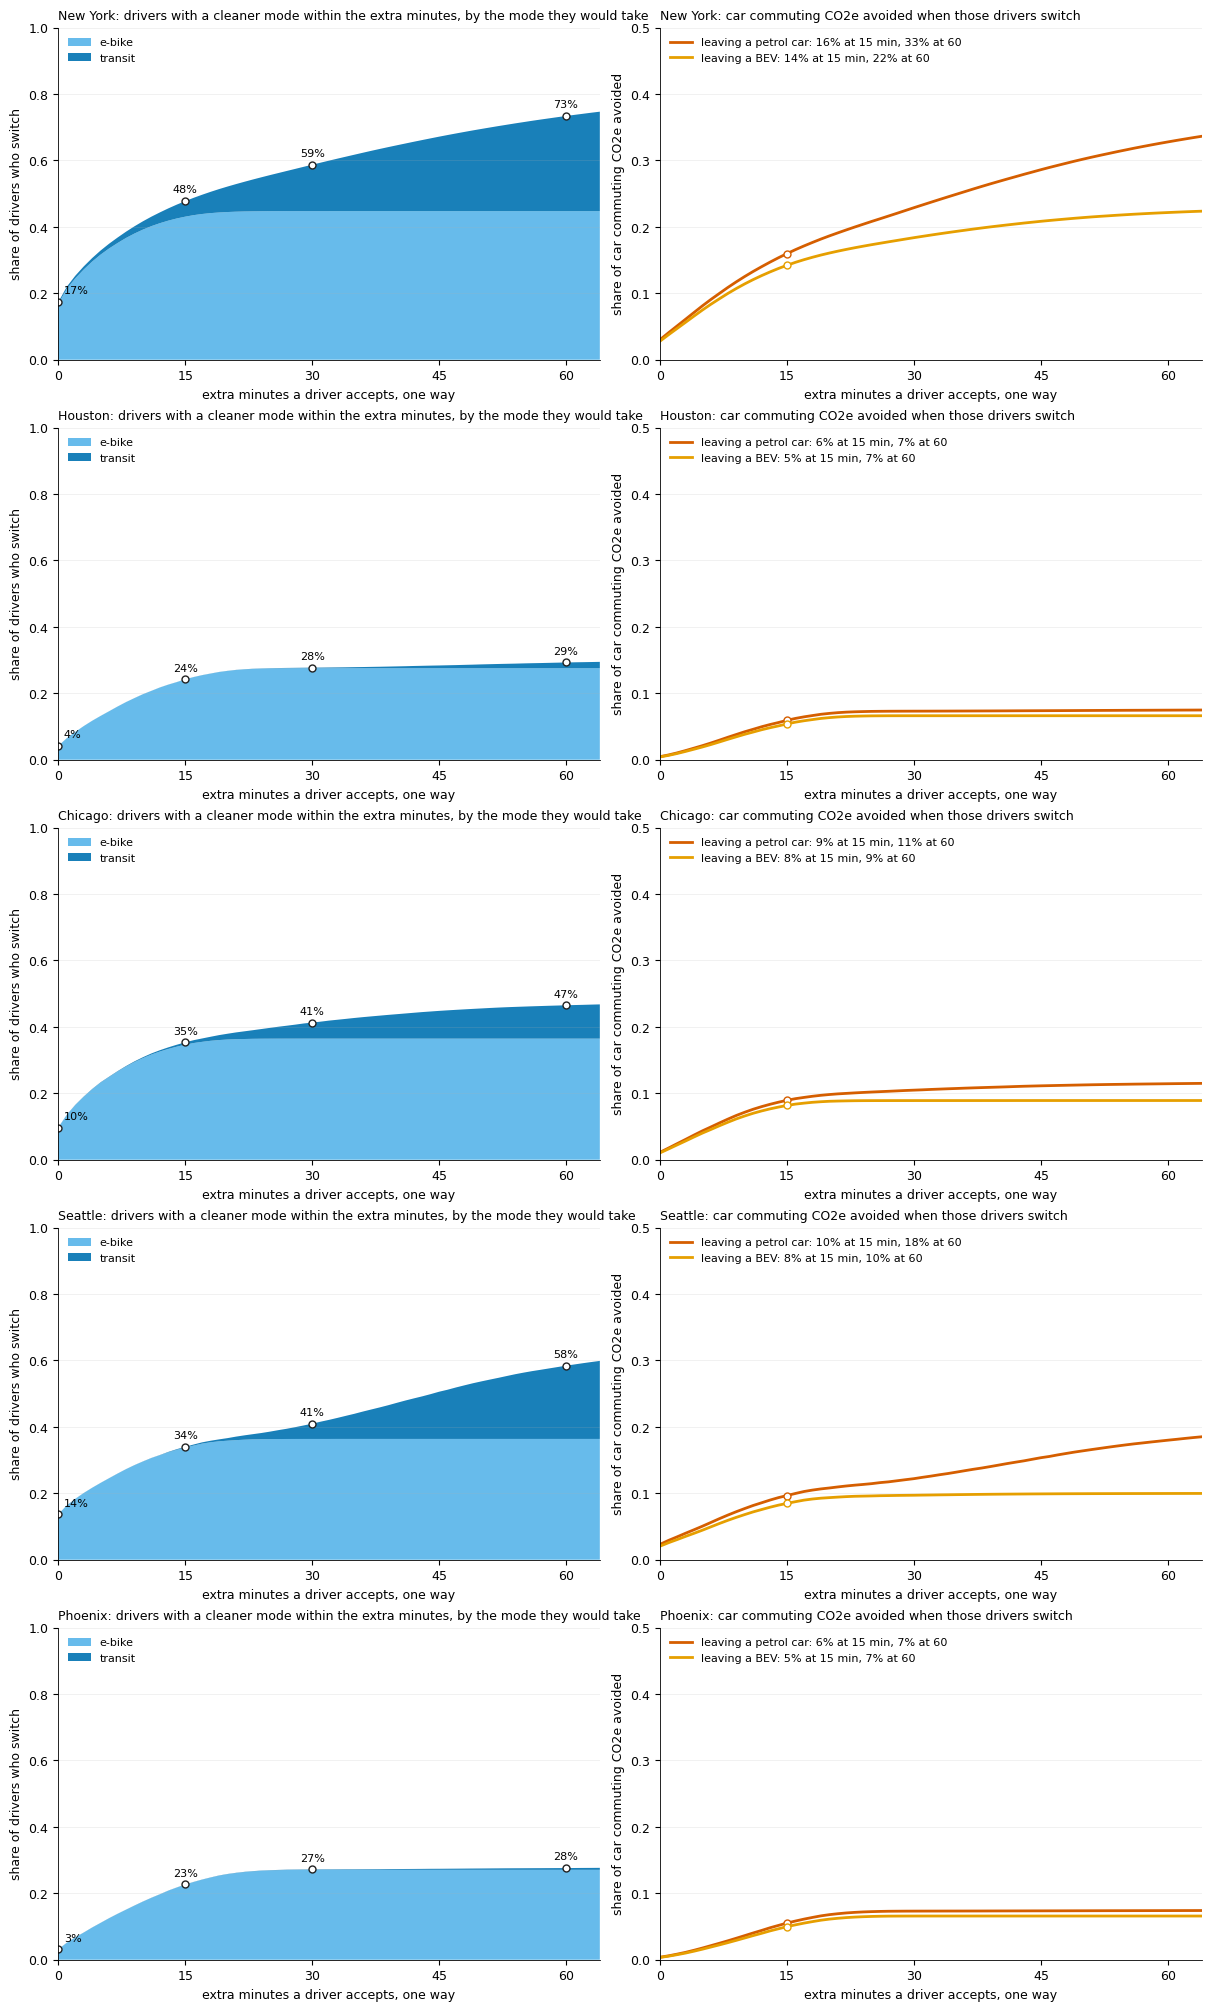

shares of drivers, at the labelled margins:


e-bike  transit  leave the car  \
area     car they leave extra minutes                                   
Chicago  BEV scenario   0               0.097    0.000          0.097   
                        15              0.346    0.001          0.348   
                        30              0.365    0.002          0.367   
                        60              0.365    0.003          0.368   
         petrol car     0               0.097    0.000          0.097   
                        15              0.346    0.007          0.354   
                        30              0.365    0.048          0.413   
                        60              0.365    0.100          0.465   
Houston  BEV scenario   0               0.041    0.000          0.042   
                        15              0.242    0.000          0.242   
                        30              0.276    0.000          0.276   
                        60              0.276    0.000          0.276   
         petrol car     0               0.041    0.000          0.042   
                        15              0.242    0.000          0.242   
                        30              0.276    0.002          0.277   
                        60              0.276    0.017          0.293   
New York BEV scenario   0               0.168    0.005          0.173   
                        15              0.431    0.045          0.476   
                        30              0.447    0.123          0.570   
                        60              0.447    0.219          0.666   
         petrol car     0               0.168    0.005          0.174   
                        15              0.431    0.047          0.478   
                        30              0.447    0.140          0.587   
                        60              0.447    0.286          0.734   
Phoenix  BEV scenario   0               0.031    0.000          0.031   
                        15              0.226    0.000          0.227   
                        30              0.271    0.001          0.271   
                        60              0.271    0.001          0.271   
         petrol car     0               0.031    0.000          0.031   
                        15              0.226    0.000          0.227   
                        30              0.271    0.001          0.272   
                        60              0.271    0.005          0.276   
Seattle  BEV scenario   0               0.137    0.000          0.137   
                        15              0.338    0.001          0.339   
                        30              0.364    0.012          0.376   
                        60              0.364    0.029          0.393   
         petrol car     0               0.137    0.000          0.137   
                        15              0.338    0.002          0.340   
                        30              0.364    0.046          0.410   
                        60              0.364    0.221          0.584   

                                       emissions avoided  
area     car they leave extra minutes                     
Chicago  BEV scenario   0                          0.010  
                        15                         0.082  
                        30                         0.089  
                        60                         0.089  
         petrol car     0                          0.011  
                        15                         0.089  
                        30                         0.105  
                        60                         0.114  
Houston  BEV scenario   0                          0.004  
                        15                         0.054  
                        30                         0.066  
                        60                         0.066  
         petrol car     0                          0.005  
                        15                         0.059  
                        30  

In [5]:
REFERENCES = {"petrol car": "car", "BEV scenario": "car_bev"}   # what the cleaner mode has to beat, and the colour of the car that remains

switch_rows = []
for area, table in flows.items():
    drivers = table.loc[table["minutes_car"].notna()]
    weights = drivers["workers"].to_numpy()
    extra = drivers[[f"minutes_{m}" for m in ALTERNATIVES]].to_numpy() - drivers[["minutes_car"]].to_numpy()   # NaN where the mode has no itinerary
    grams_alt = drivers[[f"grams_{m}" for m in ALTERNATIVES]].to_numpy()
    for reference, ref_mode in REFERENCES.items():
        grams_ref = drivers[f"grams_{ref_mode}"].to_numpy()
        cleaner = grams_alt < grams_ref[:, None]
        for margin in EXTRA_MINUTES:
            admissible = cleaner & (extra <= margin)
            choice = np.argmin(np.where(admissible, grams_alt, np.inf), axis=1)
            stays = ~admissible.any(axis=1)
            chosen_grams = np.where(stays, grams_ref, grams_alt[np.arange(len(drivers)), choice])
            row = {"area": area, "reference": reference, "extra_min": margin, "car": weights[stays].sum() / weights.sum(),
                   "emissions avoided": 1 - (weights * chosen_grams).sum() / (weights * grams_ref).sum()}
            for i, m in enumerate(ALTERNATIVES):
                row[m] = weights[~stays & (choice == i)].sum() / weights.sum()
            switch_rows.append(row)
switch = pd.DataFrame(switch_rows).set_index(["area", "reference", "extra_min"]).sort_index()

MARGINS_LABELLED = [0, 15, 30, 60]
SWITCH_MODES = ["e_bike", "transit"]   # the modes that ever win; the bicycle never does (see the text)

figure, axes = plt.subplots(nrows=len(AREAS), ncols=2, figsize=(12, 4 * len(AREAS)), layout="constrained")
for row, area in enumerate(AREAS):
    petrol = switch.loc[(area, "petrol car")].loc[0:EXTRA_MINUTES[-1]]
    bev = switch.loc[(area, "BEV scenario")].loc[0:EXTRA_MINUTES[-1]]

    axis = axes[row, 0]
    axis.stackplot(petrol.index, [petrol[m] for m in SWITCH_MODES], colors=[COLOURS[m] for m in SWITCH_MODES], labels=[LABELS[m] for m in SWITCH_MODES], alpha=0.9)
    leaves = 1 - petrol["car"]
    for margin in MARGINS_LABELLED:
        axis.plot(margin, leaves.loc[margin], "o", markerfacecolor="white", markeredgecolor="#222222", markersize=5)
        axis.annotate(f"{leaves.loc[margin]:.0%}", (margin, leaves.loc[margin]), xytext=(4 if margin == 0 else 0, 6), textcoords="offset points", ha="left" if margin == 0 else "center", fontsize=8)
    axis.set_xlim(0, EXTRA_MINUTES[-1])
    axis.set_ylim(0, 1)
    axis.set_xticks(range(0, EXTRA_MINUTES[-1] + 1, 15))
    axis.set_xlabel("extra minutes a driver accepts, one way")
    axis.set_ylabel("share of drivers who switch")
    axis.set_title(f"{area}: drivers with a cleaner mode within the extra minutes, by the mode they would take", loc="left", fontsize=9)
    axis.grid(axis="y", alpha=0.25, linewidth=0.5)
    axis.legend(frameon=False, fontsize=8, loc="upper left")

    axis = axes[row, 1]
    for frame, mode, label in [(petrol, "car", "leaving a petrol car"), (bev, "car_bev", "leaving a BEV")]:
        curve = frame["emissions avoided"]
        axis.plot(curve.index, curve, color=COLOURS[mode], linewidth=2, label=f"{label}: {curve.loc[15]:.0%} at 15 min, {curve.loc[60]:.0%} at 60")
        axis.plot(15, curve.loc[15], "o", markerfacecolor="white", markeredgecolor=COLOURS[mode], markersize=5)
    axis.set_xlim(0, EXTRA_MINUTES[-1])
    axis.set_ylim(0, 0.5)
    axis.set_xticks(range(0, EXTRA_MINUTES[-1] + 1, 15))
    axis.set_xlabel("extra minutes a driver accepts, one way")
    axis.set_ylabel("share of car commuting CO2e avoided")
    axis.set_title(f"{area}: car commuting CO2e avoided when those drivers switch", loc="left", fontsize=9)
    axis.grid(axis="y", alpha=0.25, linewidth=0.5)
    axis.legend(frameon=False, fontsize=8, loc="upper left")
figure.savefig(FIGURES / f"05.11-frontier-against-the-car-{RUN_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

print("shares of drivers, at the labelled margins:")
frontier_table = switch.loc[pd.IndexSlice[:, :, MARGINS_LABELLED], :].copy()
frontier_table["leave the car"] = 1 - frontier_table.pop("car")
frontier_table = frontier_table.reindex(columns=SWITCH_MODES + ["leave the car", "emissions avoided"]).rename(columns=LABELS)
frontier_table.index = frontier_table.index.set_names(["area", "car they leave", "extra minutes"])
frontier_table.round(3)


## 5. Maps by home tract

Three pairs of maps, New York beside Houston, each value the worker-weighted statistic over
the tract's residents. Tracts where fewer than half of the residents enter the statistic are
grey.

1. **The time penalty of transit against the car**: the median extra minutes of the transit
   commute, among residents with both itineraries. Diverging: blue where transit is faster,
   orange where slower.
2. **A cleaner commute within 15 minutes**: the share of residents for whom some mode (transit,
   e-bike, bicycle) emits less than the petrol car and takes at most 15 minutes more.
3. **Compliance within 15 extra minutes**: the share of driving residents whose weekly commute
   fits the 2030 budget of 7 kg when they take the cleanest mode at most 15 minutes slower than
   the car, and keep the car otherwise. The 15 is a drawn point on the frontier of step 4, set
   by `TOLERANCE_MIN`, not a value from the data or the paper.

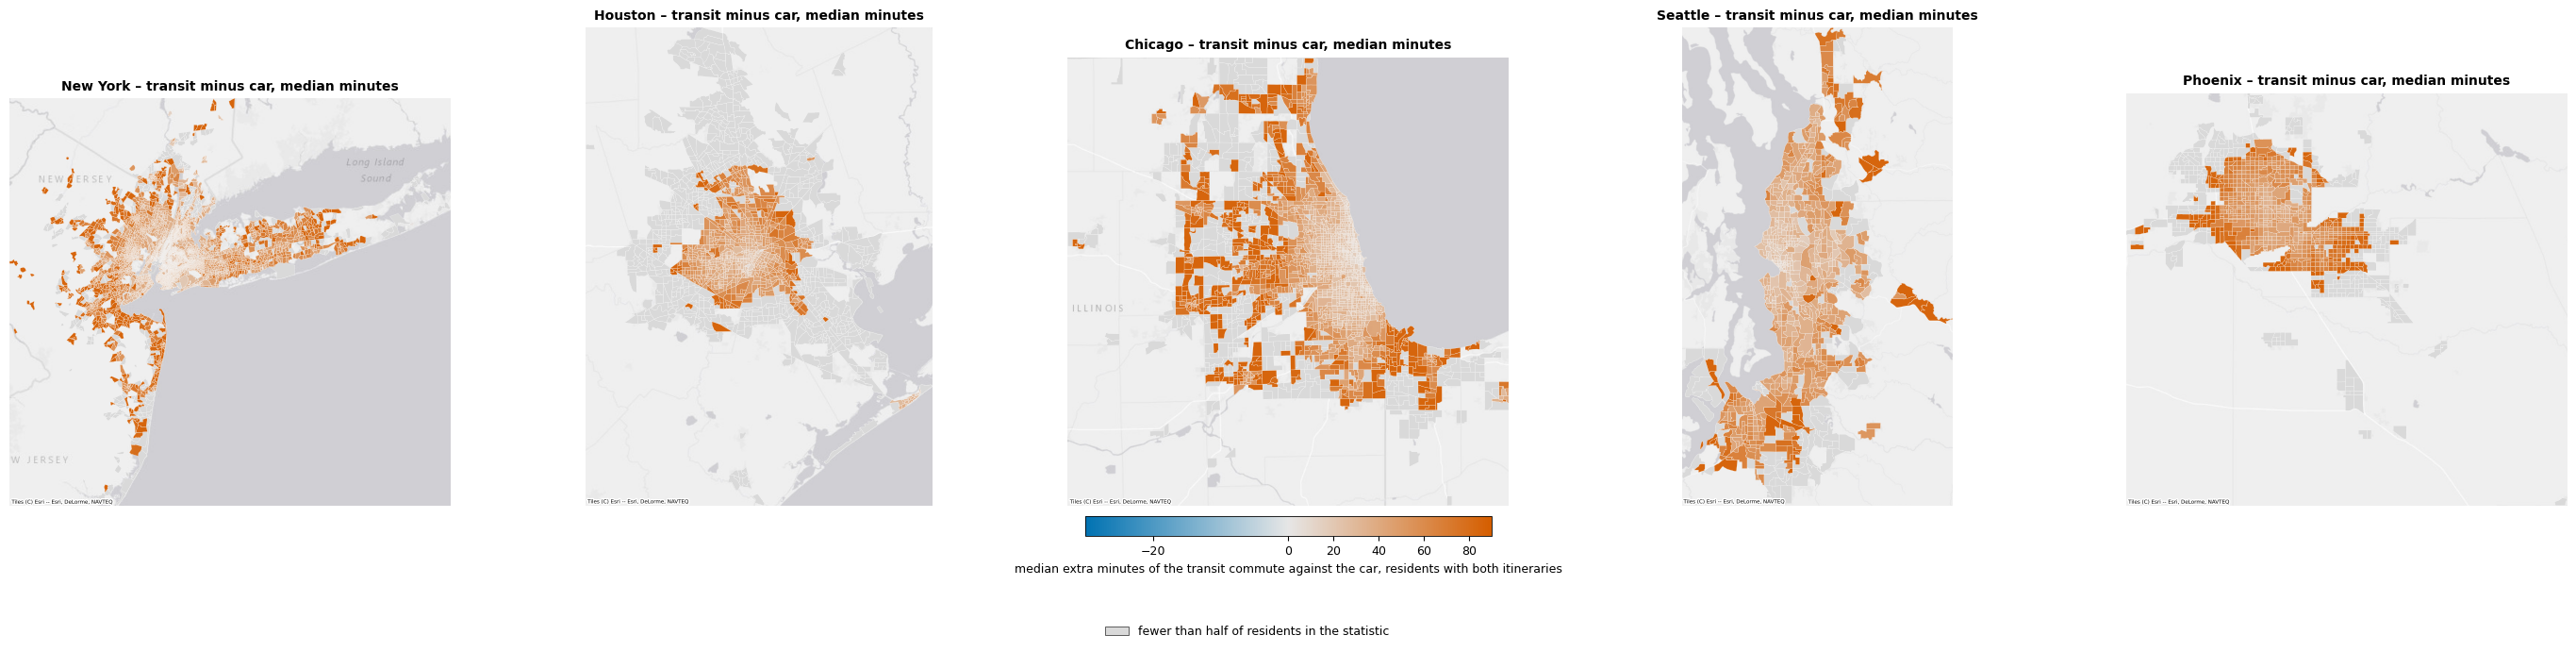

saved figures/05.11-map-transit-time-penalty-us-v4.1-centre.png


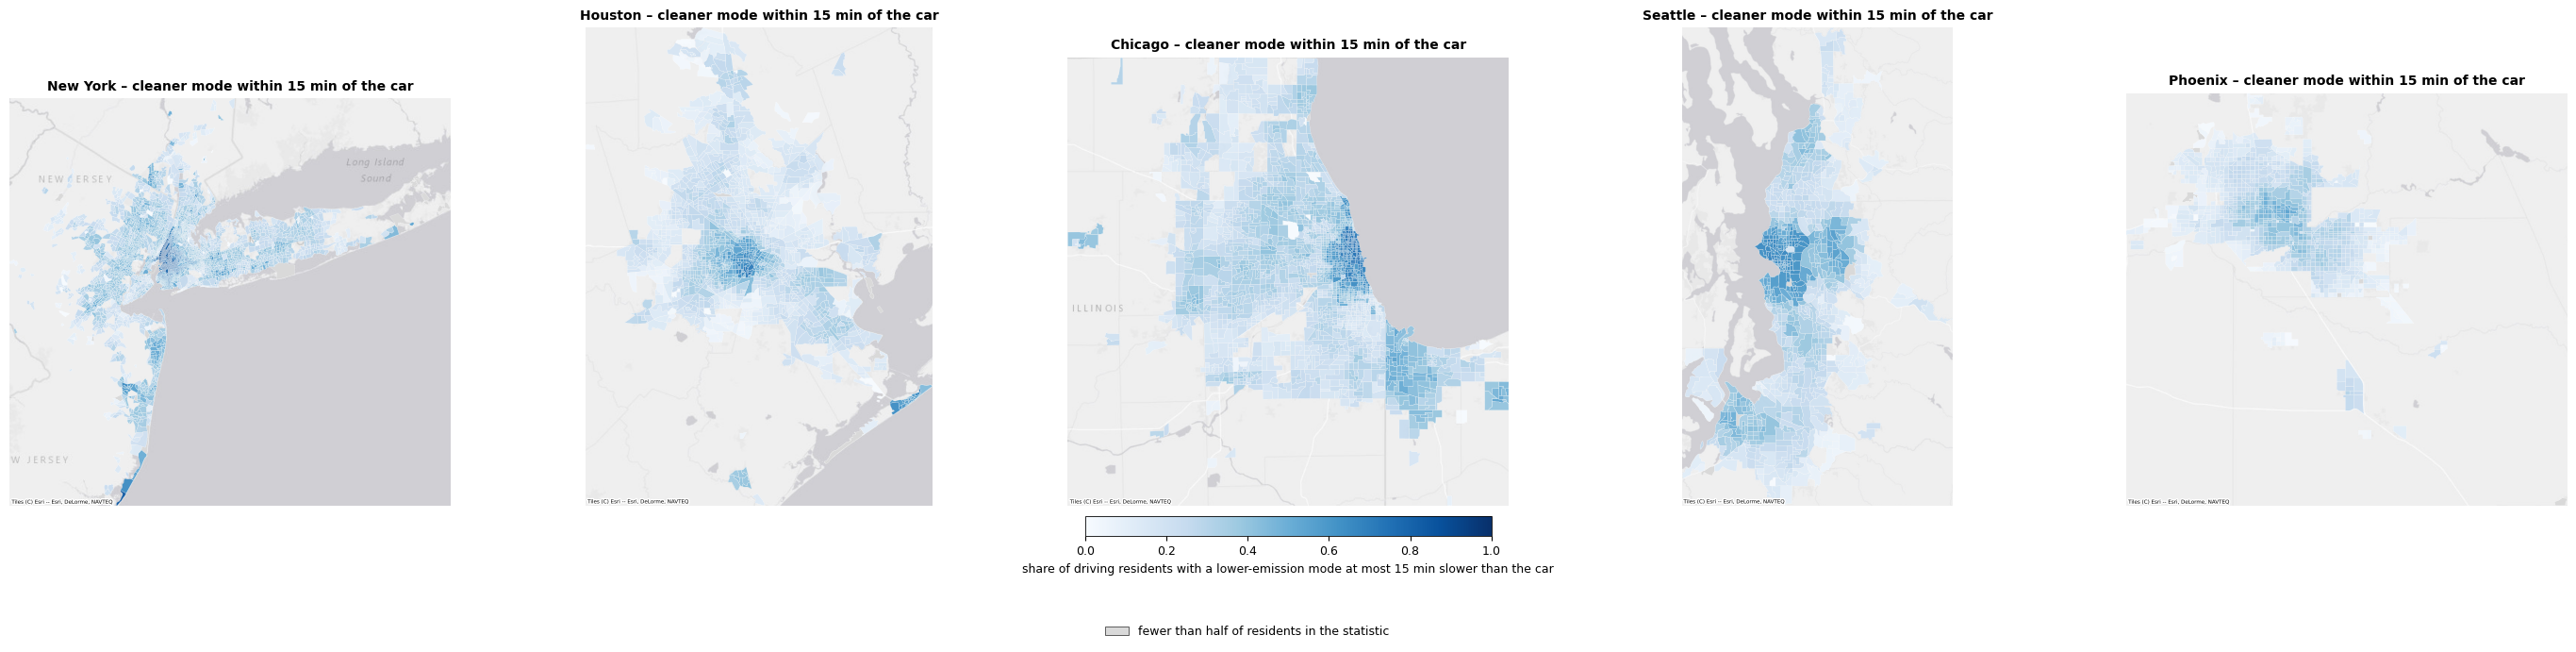

saved figures/05.11-map-cleaner-within-15min-us-v4.1-centre.png


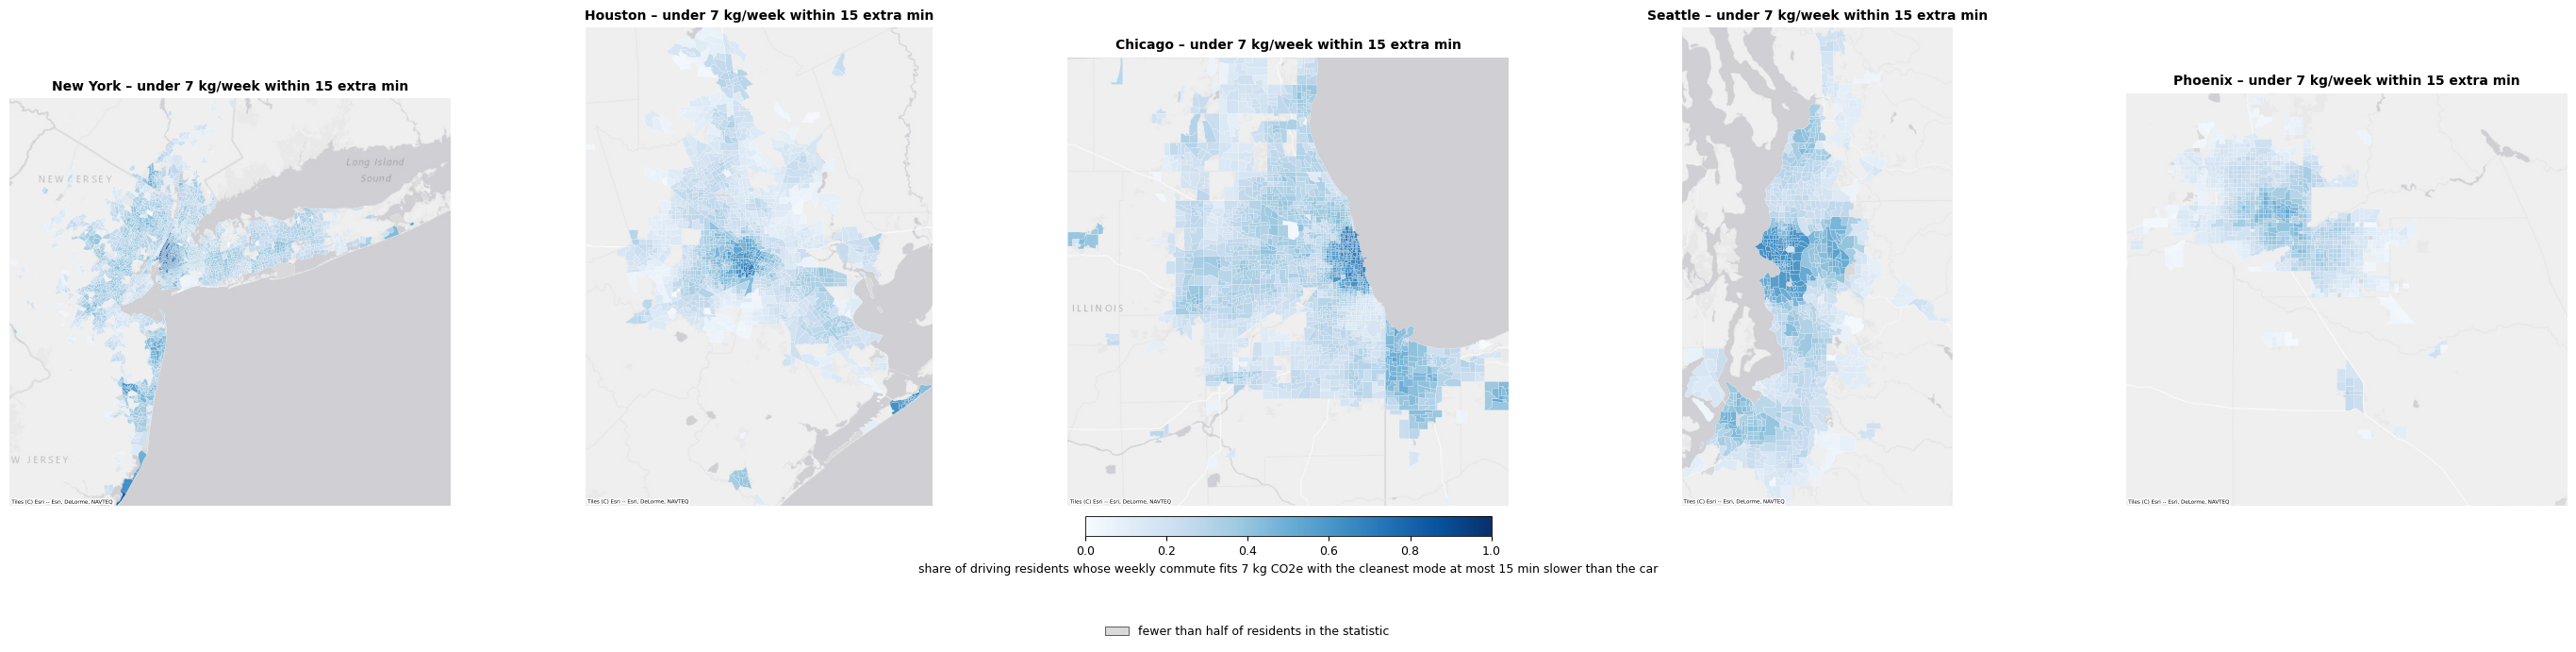

saved figures/05.11-map-compliance-7kg-15extra-min-us-v4.1-centre.png
New York: tract layer saved, 4,587 tracts
Houston: tract layer saved, 1,445 tracts
Chicago: tract layer saved, 2,153 tracts


Seattle: tract layer saved, 791 tracts
Phoenix: tract layer saved, 1,008 tracts


In [6]:
def tract_statistic(table, value, weights_mask, fn):
    # Per home tract: fn over the residents selected by weights_mask, and the share of residents selected.
    residents = table.groupby("from_id")["workers"].sum()
    sub = table.loc[weights_mask]
    covered = sub.groupby("from_id")["workers"].sum().reindex(residents.index, fill_value=0) / residents
    stat = sub.groupby("from_id").apply(lambda r: fn(r), include_groups=False).reindex(residents.index)
    return pd.DataFrame({"value": stat, "coverage": covered}).rename_axis("tract").reset_index()


def draw_map(axis, area, layer, column, cmap, norm, title, coverage_floor=0.5):
    data = tracts[area].merge(layer, on="tract", how="left")
    data["value"] = data["value"].where(data["coverage"] >= coverage_floor)
    missing = data.loc[data["value"].isna()]
    if len(missing):
        missing.plot(ax=axis, color=NO_DATA, edgecolor="white", linewidth=0.15)
    present = data.loc[data["value"].notna()]
    if len(present):
        present.plot(ax=axis, column="value", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.15, alpha=0.95)
    west, south, east, north = data.total_bounds
    axis.set_xlim(west, east)
    axis.set_ylim(south, north)
    try:
        ctx.add_basemap(axis, source=BASEMAP, attribution_size=4)
    except Exception as error:
        print(f"{area}: basemap not drawn ({type(error).__name__}: {str(error)[:100]})")
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.set_aspect("equal")
    axis.set_title(title, fontsize=10, fontweight="bold", pad=6)
    return data


def map_pair(layers, cmap, norm, titles, colorbar_label, filename, extra_handle=None):
    figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 7))
    for axis, area in zip(axes, AREAS):
        draw_map(axis, area, layers[area], "value", cmap, norm, f"{area} – {titles}")
    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    bar = figure.colorbar(mappable, ax=axes, orientation="horizontal", fraction=0.04, pad=0.02, shrink=0.5)
    bar.set_label(colorbar_label)
    figure.legend(handles=[mpatches.Patch(facecolor=NO_DATA, edgecolor="#444444", linewidth=0.6, label="fewer than half of residents in the statistic")],
                  loc="lower center", bbox_to_anchor=(0.5, -0.06), frameon=False, fontsize=9)
    png = FIGURES / filename
    figure.savefig(png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"saved {png}")


# 1. The time penalty of transit against the car.
penalty = {}
for area, table in flows.items():
    both = table["minutes_car"].notna() & table["minutes_transit"].notna()
    extra = table["minutes_transit"] - table["minutes_car"]
    penalty[area] = tract_statistic(table.assign(extra=extra), "extra", both, lambda r: weighted_median(r["extra"], r["workers"]))
map_pair(penalty, DIVERGING, mcolors.TwoSlopeNorm(vmin=-30, vcenter=0, vmax=90), "transit minus car, median minutes",
         "median extra minutes of the transit commute against the car, residents with both itineraries", f"05.11-map-transit-time-penalty-{RUN_TAG}.png")

# 2. A cleaner commute within TOLERANCE_MIN of the car.
cleaner = {}
for area, table in flows.items():
    drivers = table["minutes_car"].notna()
    has_cleaner = np.zeros(len(table), dtype=bool)
    for mode in ALTERNATIVES:
        has_cleaner |= (table[f"minutes_{mode}"] <= table["minutes_car"] + TOLERANCE_MIN) & (table[f"grams_{mode}"] < table["grams_car"])
    layer = tract_statistic(table.assign(cleaner=has_cleaner.astype(float)), "cleaner", drivers, lambda r: np.average(r["cleaner"], weights=r["workers"]))
    cleaner[area] = layer
map_pair(cleaner, SEQUENTIAL, mcolors.Normalize(vmin=0, vmax=1), f"cleaner mode within {TOLERANCE_MIN} min of the car",
         f"share of driving residents with a lower-emission mode at most {TOLERANCE_MIN} min slower than the car", f"05.11-map-cleaner-within-{TOLERANCE_MIN}min-{RUN_TAG}.png")

# 3. Compliance with the 2030 budget when drivers take the cleanest mode within TOLERANCE_MIN of the car.
compliance = {}
for area, table in flows.items():
    drivers = table["minutes_car"].notna()
    sub = table.loc[drivers]
    extra = sub[[f"minutes_{m}" for m in ALTERNATIVES]].to_numpy() - sub[["minutes_car"]].to_numpy()
    grams_alt = sub[[f"grams_{m}" for m in ALTERNATIVES]].to_numpy()
    admissible = (grams_alt < sub[["grams_car"]].to_numpy()) & (extra <= TOLERANCE_MIN)
    grams = np.where(admissible, grams_alt, np.inf).min(axis=1)
    grams = np.where(np.isinf(grams), sub["grams_car"].to_numpy(), grams)
    under = pd.Series(0.0, index=table.index)
    under.loc[sub.index] = (grams * WEEKLY_PER_GRAM <= BUDGETS_KG["2030 budget, 7 kg/week"]).astype(float)
    compliance[area] = tract_statistic(table.assign(under=under), "under", drivers, lambda r: np.average(r["under"], weights=r["workers"]))
map_pair(compliance, SEQUENTIAL, mcolors.Normalize(vmin=0, vmax=1), f"under 7 kg/week within {TOLERANCE_MIN} extra min",
         f"share of driving residents whose weekly commute fits 7 kg CO2e with the cleanest mode at most {TOLERANCE_MIN} min slower than the car", f"05.11-map-compliance-7kg-{TOLERANCE_MIN}extra-min-{RUN_TAG}.png")

# The tract layers, saved for reuse.
for area, folder in AREAS.items():
    out = pd.concat([penalty[area].rename(columns={"value": "transit_extra_minutes_median", "coverage": "share_with_both_itineraries"}),
                     cleaner[area].drop(columns="tract").rename(columns={"value": f"share_cleaner_within_{TOLERANCE_MIN}min", "coverage": "share_drivers"}),
                     compliance[area].drop(columns=["tract", "coverage"]).rename(columns={"value": f"share_under_7kg_within_{TOLERANCE_MIN}extra_min"})], axis=1)
    out.to_parquet(folder / f"tract-time-vs-emissions-{RUN_TAG}-{YEAR}.parquet", index=False)
    print(f"{area}: tract layer saved, {len(out):,} tracts")